
**Course:** Semester V — SI Lab  
**Project Title:** Crop Yield Prediction System  
**Student Name:** Sanchali Chandankhede | **Roll No:** 20  



---
## Section 1: Web Scraping



In [1]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

url = "https://news.ycombinator.com/"
data = []

try:
    headers = {
        "User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36"
    }
    response = requests.get(url, headers=headers, timeout=20)
    response.raise_for_status()
    print(f"Status Code: {response.status_code} (Success)")

    soup = BeautifulSoup(response.text, "html.parser")
    headlines = soup.find_all("span", class_="titleline")

    for item in headlines[:10]:
        link = item.find("a")
        if link and link.get("href"):
            data.append({
                "Title": link.get_text(strip=True),
                "URL": link.get("href")
            })

    hn_df = pd.DataFrame(data)
    print(f"\nScraped {len(hn_df)} articles from Hacker News:")
    display(hn_df)

    hn_df.to_csv("hacker_news.csv", index=False)
    print("\n✓ Scraped data successfully saved to 'hacker_news.csv'.")

except requests.exceptions.RequestException as req_err:
    print(f"Network / HTTP error during web scraping: {req_err}")
except Exception as err:
    print(f"An unexpected error occurred during scraping: {err}")


Status Code: 200 (Success)

Scraped 10 articles from Hacker News:


,Title,URL
0,"Ten days later, Git on macOS still trusts the ...",https://emudhra.we-have-a-problem.com/apple.html
1,Kentucky man becomes the first humanist grante...,https://religionnews.com/2026/10/26/in-a-first...
2,"Harvey raised 500M for legal AI, I built the s...",https://github.com/thomasunise/casecite
3,Start Doing Graph Theory,https://vertex.degree/
4,ICE Is Running One of the Largest Anti-Left Su...,https://www.wired.com/story/ice-is-running-one...
5,"Unveiling The Grid: PCBs made in America, twic...",https://www.circuithub.com/post/unveiling-the-...
6,Git for the US Code,https://lexifina.com/blog/git-for-the-us-code
7,The Agent SDK,https://cursor.com/blog/agent-sdk
8,Emacs Turns 50,https://www.technologyreview.com/2026/10/20/11...
9,Show HN: Nasscad – local-first 3D CAD for brow...,https://www.nasscad.com/NASSCAD_V4_7_0.htm



✓ Scraped data successfully saved to 'hacker_news.csv'.



## Section 2: Load the Actual Crop-Yield Dataset



In [2]:
import pandas as pd
import numpy as np

# Load the actual crop yield dataset
csv_path = "yield_df.csv"
df = pd.read_csv(csv_path)

print("Original columns in CSV:")
print(df.columns.tolist())

# Remove unnecessary index column if present
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

# Rename columns consistently with the report and Streamlit application
rename_map = {
    "Area": "Country",
    "Item": "Crop",
    "hg/ha_yield": "Yield",
    "average_rain_fall_mm_per_year": "Rainfall",
    "pesticides_tonnes": "Pesticides",
    "avg_temp": "Temperature"
}
df = df.rename(columns=rename_map)

print(f"\nDataset loaded successfully with shape: {df.shape}")
df.head()


Original columns in CSV:
['Unnamed: 0', 'Area', 'Item', 'Year', 'hg/ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']

Dataset loaded successfully with shape: (28242, 7)


,Country,Crop,Year,Yield,Rainfall,Pesticides,Temperature
0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37



## Section 3: Basic Data Exploration and Preprocessing



In [3]:
# 1. Dataset structure and information
print("Dataset Shape:", df.shape)
print("\nColumn Information and Data Types:")
df.info()
print(f"Number of unique countries: {df['Country'].nunique()}")

Dataset Shape: (28242, 7)

Column Information and Data Types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28242 entries, 0 to 28241
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Country      28242 non-null  object 
 1   Crop         28242 non-null  object 
 2   Year         28242 non-null  int64  
 3   Yield        28242 non-null  int64  
 4   Rainfall     28242 non-null  float64
 5   Pesticides   28242 non-null  float64
 6   Temperature  28242 non-null  float64
dtypes: float64(3), int64(2), object(2)
memory usage: 1.5+ MB
Number of unique countries: 101


In [7]:
# 2. Check missing values and duplicate records
print("\nMissing values per column:")
print(df.isnull().sum())
print(f"Number of unique crops: {df['Crop'].nunique()}")

print("\nDuplicate records check:")
print(f"Total rows in dataset: {len(df):,}")
print(f"Repeated feature combinations across records: {df.duplicated().sum():,}")


Missing values per column:
Country        0
Crop           0
Year           0
Yield          0
Rainfall       0
Pesticides     0
Temperature    0
dtype: int64
Number of unique crops: 10

Duplicate records check:
Total rows in dataset: 28,242
Repeated feature combinations across records: 2,310


In [9]:
# 3. Numeric conversion and cleaning
numeric_cols = ["Year", "Rainfall", "Pesticides", "Temperature", "Yield"]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Handle any missing values across required features and target
df = df.dropna(subset=numeric_cols + ["Country", "Crop"]).reset_index(drop=True)
df["Country"] = df["Country"].astype(str)
df["Crop"] = df["Crop"].astype(str)

print(f"\nDataset Shape after verification: {df.shape}")

# 4. Summary statistics
print("\nNumerical Features Summary:")
display(df.describe().round(2))

# 5. Dataset coverage
print(f"Number of unique countries: {df['Country'].nunique()}")
print(f"Number of unique crops: {df['Crop'].nunique()}")
print(f"Available crops: {sorted(df['Crop'].unique().tolist())}")
print(f"Year range: {int(df['Year'].min())} to {int(df['Year'].max())}")



Dataset Shape after verification: (28242, 7)

Numerical Features Summary:


,Year,Yield,Rainfall,Pesticides,Temperature
count,28242.00,28242.00,28242.00,28242.00,28242.00
mean,2001.54,77053.33,1149.06,37076.91,20.54
std,7.05,84956.61,709.81,59958.78,6.31
min,1990.00,50.00,51.00,0.04,1.30
25%,1995.00,19919.25,593.00,1702.00,16.70
50%,2001.00,38295.00,1083.00,17529.44,21.51
75%,2008.00,104676.75,1668.00,48687.88,26.00
max,2013.00,501412.00,3240.00,367778.00,30.65


Number of unique countries: 101
Number of unique crops: 10
Available crops: ['Cassava', 'Maize', 'Plantains and others', 'Potatoes', 'Rice, paddy', 'Sorghum', 'Soybeans', 'Sweet potatoes', 'Wheat', 'Yams']
Year range: 1990 to 2013



## Section 4: Essential Data Visualization


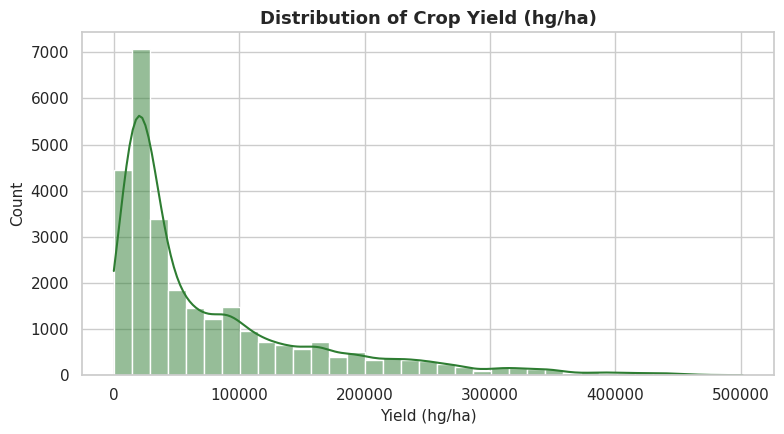

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Crop Yield Distribution
plt.figure(figsize=(8, 4.5))
sns.histplot(df["Yield"], bins=35, kde=True, color="#2e7d32")
plt.title("Distribution of Crop Yield (hg/ha)", fontsize=13, fontweight="bold")
plt.xlabel("Yield (hg/ha)", fontsize=11)
plt.ylabel("Count", fontsize=11)
plt.tight_layout()
plt.show()


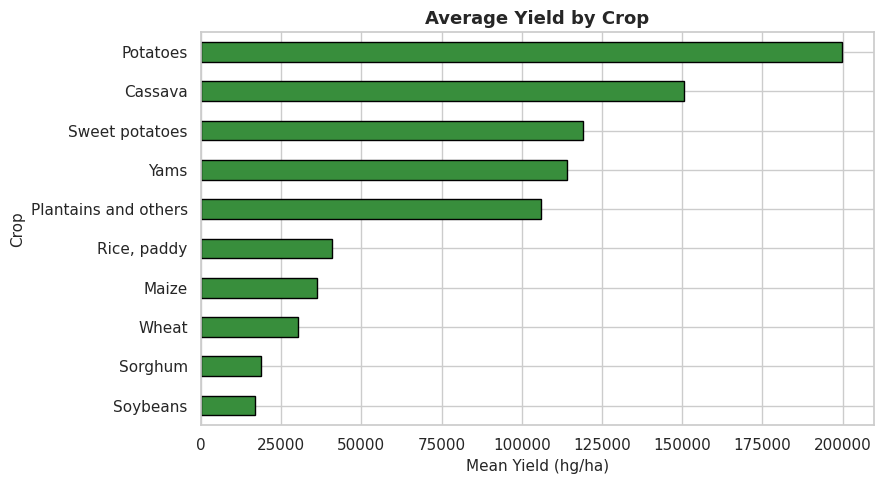

In [12]:
# 2. Average Yield by Crop
plt.figure(figsize=(9, 5))
mean_yield_by_crop = df.groupby("Crop")["Yield"].mean().sort_values(ascending=True)
mean_yield_by_crop.plot(kind="barh", color="#388e3c", edgecolor="black")
plt.title("Average Yield by Crop", fontsize=13, fontweight="bold")
plt.xlabel("Mean Yield (hg/ha)", fontsize=11)
plt.ylabel("Crop", fontsize=11)
plt.tight_layout()
plt.show()


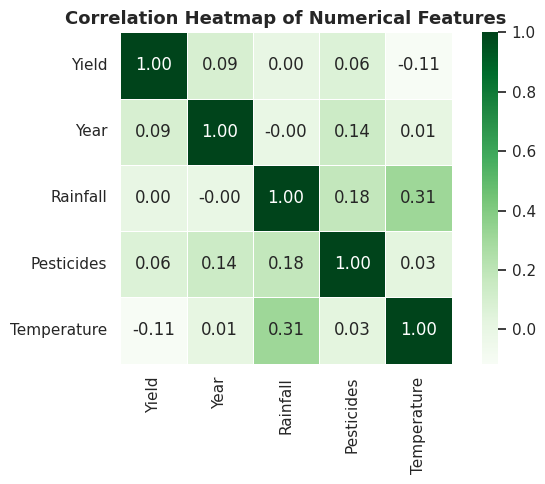

In [13]:
# 3. Correlation Heatmap for Numerical Features
plt.figure(figsize=(7, 5))
corr_matrix = df[["Yield", "Year", "Rainfall", "Pesticides", "Temperature"]].corr()
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="Greens",
    cbar=True,
    square=True,
    linewidths=0.5
)
plt.title("Correlation Heatmap of Numerical Features", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()



## Section 5: Crop Yield Regression Modeling


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Define features and target
NUMERIC_FEATURES = ["Year", "Rainfall", "Pesticides", "Temperature"]
CATEGORICAL_FEATURES = ["Country", "Crop"]
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES
TARGET = "Yield"

X = df[FEATURES]
y = df[TARGET]

# Split 80% train, 20% test with random_state=42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print(f"Training samples: {len(X_train):,}")
print(f"Testing samples:  {len(X_test):,}")

# Construct scikit-learn preprocessing pipelines
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, NUMERIC_FEATURES),
    ("categorical", categorical_pipeline, CATEGORICAL_FEATURES)
])

# Define the five regression models matching project specifications
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.01, max_iter=10000),
    "Decision Tree": DecisionTreeRegressor(max_depth=20, random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=150, random_state=42, n_jobs=-1
    )
}

# Train pipelines and generate predictions
fitted_pipelines = {}
predictions = {}

for name, regressor in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", regressor)
    ])
    pipeline.fit(X_train, y_train)
    fitted_pipelines[name] = pipeline
    predictions[name] = pipeline.predict(X_test)
    print(f"✓ Trained: {name}")


Training samples: 22,593
Testing samples:  5,649
✓ Trained: Linear Regression
✓ Trained: Ridge Regression


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:656: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 17511920655874.209, tolerance: 16285698450.256039
  model = cd_fast.sparse_enet_coordinate_descent(


✓ Trained: Lasso Regression
✓ Trained: Decision Tree
✓ Trained: Random Forest


## Section 6: Model Evaluation and Essential Tests


In [15]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

# 1. Compute evaluation metrics
results = []
for name in models.keys():
    preds = predictions[name]
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)
    results.append({
        "Model": name,
        "MAE (hg/ha)": round(mae, 2),
        "RMSE (hg/ha)": round(rmse, 2),
        "R² Score": round(r2, 4)
    })

results_df = pd.DataFrame(results).sort_values("RMSE (hg/ha)").reset_index(drop=True)
print("=== REGRESSION MODEL COMPARISON TABLE ===")
display(results_df)

# 2. Select best model based on lowest test-set RMSE
best_model_name = results_df.loc[0, "Model"]
best_pipeline = fitted_pipelines[best_model_name]
print(f"\nBest Model Selected: {best_model_name}")
print(f"Lowest RMSE: {results_df.loc[0, 'RMSE (hg/ha)']:,} hg/ha")
print(f"R² Score:    {results_df.loc[0, 'R² Score']}")



=== REGRESSION MODEL COMPARISON TABLE ===


,Model,MAE (hg/ha),RMSE (hg/ha),R² Score
0,Random Forest,3476.83,9451.39,0.9877
1,Decision Tree,4628.91,12586.50,0.9782
2,Ridge Regression,29541.31,42142.41,0.7552
3,Lasso Regression,29582.28,42144.01,0.7551
4,Linear Regression,29582.52,42144.05,0.7551



Best Model Selected: Random Forest
Lowest RMSE: 9,451.39 hg/ha
R² Score:    0.9877


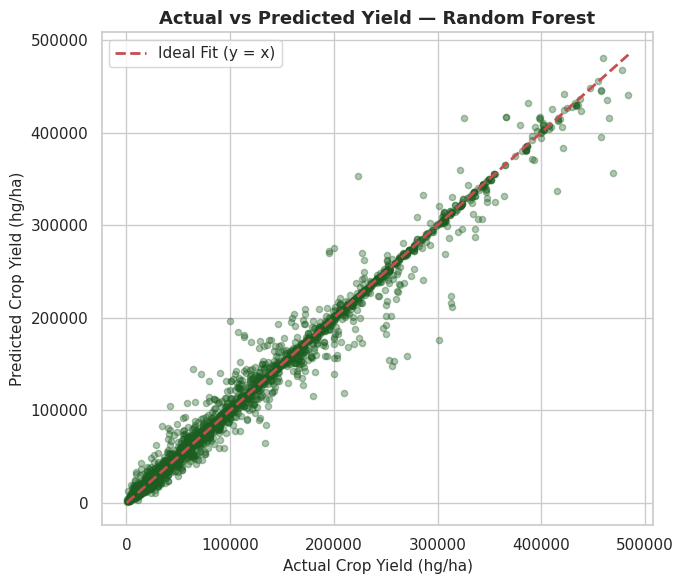

In [16]:
# Actual vs Predicted Plot for Best Model
best_preds = predictions[best_model_name]

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_preds, alpha=0.35, color="#1b5e20", s=20)
min_val = min(y_test.min(), best_preds.min())
max_val = max(y_test.max(), best_preds.max())
plt.plot([min_val, max_val], [min_val, max_val], "r--", lw=2, label="Ideal Fit (y = x)")
plt.title(f"Actual vs Predicted Yield — {best_model_name}", fontsize=13, fontweight="bold")
plt.xlabel("Actual Crop Yield (hg/ha)", fontsize=11)
plt.ylabel("Predicted Crop Yield (hg/ha)", fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()


### Save the Best Model


In [17]:
import joblib

# Save the best model pipeline using Joblib
joblib.dump(best_pipeline, "best_model.pkl")
print("Best model pipeline successfully saved to 'best_model.pkl'")


Best model pipeline successfully saved to 'best_model.pkl'
